# Banking Customer Intent Classification (Banking77)

**Business question:** A bank's digital assistant receives thousands of free-text customer questions a day.
Can we route each one to the right intent automatically — and, just as important, *know when not to trust the model*
and hand the query to a person?

This notebook rebuilds, on public data, the kind of query classifier I built at U.S. Bank for the mobile voice assistant.

**Dataset:** [Banking77](https://github.com/PolyAI-LDN/task-specific-datasets) (PolyAI, CC BY 4.0) — 13,083 real-style
customer queries labeled with 77 fine-grained banking intents (e.g., `card_arrival`, `lost_or_stolen_card`, `top_up_failed`).

**Approach**
1. Explore the data
2. Select models with 5-fold cross-validation on the training set only (the test set is touched once)
3. Evaluate on the held-out test set with bootstrap confidence intervals and a McNemar significance test
4. Error analysis: which intents get confused, and why
5. Confidence-based routing: how much can be automated at a target accuracy?
6. Learning curve: would more labeled data help?

In [1]:
import sys, warnings, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, classification_report

import intent

FIG = Path.cwd().parent / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left", "figure.dpi": 110,
})
pd.set_option("display.width", 140)
train, test = intent.load_data()
print(f"train: {len(train):,} rows | test: {len(test):,} rows | intents: {train.category.nunique()}")
train.sample(5, random_state=intent.SEED)

train: 10,003 rows | test: 3,080 rows | intents: 77


,text,category
6883,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer


## 1. Explore the data

Examples per intent (train): min 35, median 127, max 187
Test set: exactly 40 examples per intent (balanced)
Query length: median 10 words, 95th percentile 29 words


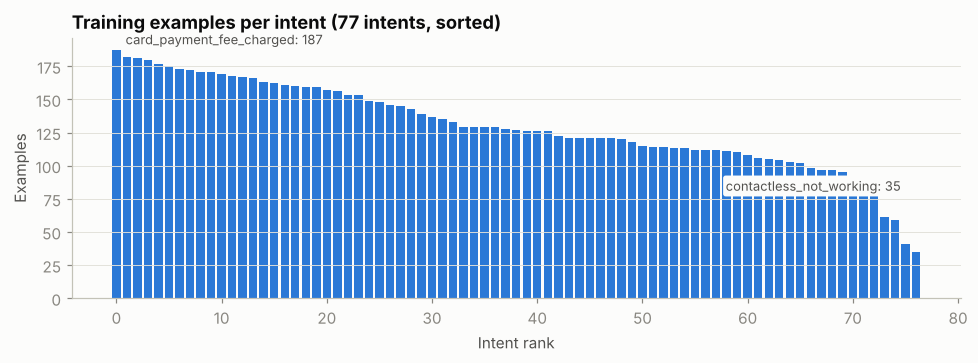

In [2]:
counts = train.category.value_counts()
lengths = train.text.str.split().str.len()
print(f"Examples per intent (train): min {counts.min()}, median {counts.median():.0f}, max {counts.max()}")
print(f"Test set: exactly {test.category.value_counts().unique()[0]} examples per intent (balanced)")
print(f"Query length: median {lengths.median():.0f} words, 95th percentile {lengths.quantile(.95):.0f} words")

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(range(len(counts)), counts.values, color=BLUE, width=0.8)
ax.set(title="Training examples per intent (77 intents, sorted)", xlabel="Intent rank", ylabel="Examples")
ax.grid(axis="x", visible=False)
for i in (0, len(counts) - 1):
    ax.annotate(f"{counts.index[i]}: {counts.iloc[i]}", (i, counts.iloc[i]), textcoords="offset points",
                xytext=(6, 4) if i == 0 else (-10, 40), ha="left" if i == 0 else "right", fontsize=8.5, color=INK2,
                bbox=dict(boxstyle="round,pad=0.2", fc=SURF, ec="none"))
fig.tight_layout(); fig.savefig(FIG / "class_balance.png", bbox_inches="tight"); plt.show()

**Takeaways:** queries are short (about 10 words), so every word carries signal. The training set is moderately
imbalanced (roughly 5:1 between the largest and smallest intent), while the test set is perfectly balanced — so
**macro-F1** (every intent weighted equally) is reported alongside accuracy.

## 2. Model selection with cross-validation

Four candidates, from the simplest bag-of-words baseline (the approach I used at U.S. Bank) to richer TF-IDF models.
Character n-grams are added because customer text is full of typos and word variants ("top up", "top-up", "topped up").
Hyperparameters are tuned with 5-fold stratified CV **on the training set only**.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=intent.SEED)
results, fitted = [], {}
for name, (pipe, grid) in intent.build_models().items():
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="accuracy", n_jobs=-1, refit=True).fit(train.text, train.category)
    i = gs.best_index_
    results.append({"model": name, "best_params": gs.best_params_,
                    "cv_accuracy": gs.cv_results_["mean_test_score"][i],
                    "cv_std": gs.cv_results_["std_test_score"][i], "minutes": (time.time() - t0) / 60})
    fitted[name] = gs.best_estimator_
cv_table = pd.DataFrame(results).sort_values("cv_accuracy", ascending=False).reset_index(drop=True)
cv_table.style.format({"cv_accuracy": "{:.2%}", "cv_std": "{:.2%}", "minutes": "{:.1f}"})

,model,best_params,cv_accuracy,cv_std,minutes
0,TF-IDF words+chars + Linear SVM,{'clf__C': 0.5},90.17%,0.20%,0.6
1,TF-IDF words+chars + Logistic Regression,{'clf__C': 30},90.10%,0.32%,3.2
2,TF-IDF words + Logistic Regression,{'clf__C': 50},87.95%,0.48%,2.1
3,Bag-of-words + Naive Bayes,{'clf__alpha': 0.1},84.76%,0.84%,0.0


## 3. Held-out test evaluation

The CV winner is chosen *before* looking at the test set. All four are then scored on test for comparison,
with 95% bootstrap confidence intervals.

In [4]:
best_name = cv_table.loc[0, "model"]
baseline_name = "Bag-of-words + Naive Bayes"
preds, rows = {}, []
for name, model in fitted.items():
    p = model.predict(test.text); preds[name] = p
    lo, hi = intent.bootstrap_ci(test.category, p)
    rows.append({"model": name, "test_accuracy": accuracy_score(test.category, p),
                 "ci_low": lo, "ci_high": hi, "macro_f1": f1_score(test.category, p, average="macro")})
test_table = pd.DataFrame(rows).sort_values("test_accuracy", ascending=False).reset_index(drop=True)
print("Selected by CV:", best_name)
test_table.style.format({c: "{:.2%}" for c in ["test_accuracy", "ci_low", "ci_high", "macro_f1"]})

Selected by CV: TF-IDF words+chars + Linear SVM


,model,test_accuracy,ci_low,ci_high,macro_f1
0,TF-IDF words+chars + Logistic Regression,91.46%,90.49%,92.47%,91.49%
1,TF-IDF words+chars + Linear SVM,91.30%,90.29%,92.34%,91.31%
2,TF-IDF words + Logistic Regression,89.29%,88.15%,90.42%,89.31%
3,Bag-of-words + Naive Bayes,86.23%,85.03%,87.50%,86.20%


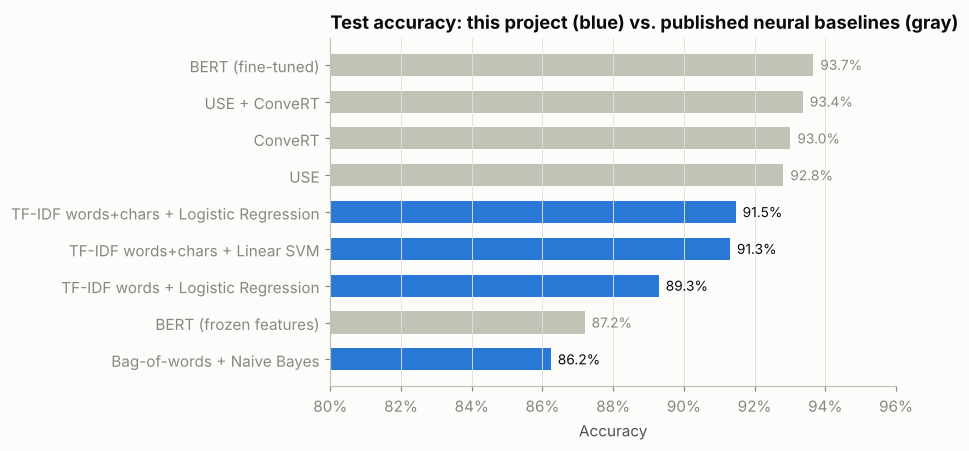

In [5]:
published = pd.DataFrame({"model": ["BERT (frozen features)", "USE", "ConveRT", "USE + ConveRT", "BERT (fine-tuned)"],
                          "test_accuracy": [0.8719, 0.9281, 0.9301, 0.9336, 0.9366]})
plot_df = pd.concat([test_table[["model", "test_accuracy"]].assign(src="This project"),
                     published.assign(src="Casanueva et al. (2020)")]).sort_values("test_accuracy")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
colors = [BLUE if s == "This project" else BASE for s in plot_df.src]
ax.barh(plot_df.model, plot_df.test_accuracy, color=colors, height=0.6)
for y, (v, s) in enumerate(zip(plot_df.test_accuracy, plot_df.src)):
    ax.text(v + 0.002, y, f"{v:.1%}", va="center", fontsize=9, color=INK if s == "This project" else MUTED)
ax.set(xlim=(0.80, 0.96), title="Test accuracy: this project (blue) vs. published neural baselines (gray)", xlabel="Accuracy")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "model_comparison.png", bbox_inches="tight"); plt.show()

In [6]:
mc = intent.mcnemar(test.category, preds[best_name], preds[baseline_name])
print(f"McNemar test — {best_name} vs. {baseline_name}")
print(f"  best right / baseline wrong: {mc['a_right_b_wrong']}")
print(f"  baseline right / best wrong: {mc['b_right_a_wrong']}")
print(f"  exact p-value: {mc['p_value']:.2e}")

McNemar test — TF-IDF words+chars + Linear SVM vs. Bag-of-words + Naive Bayes
  best right / baseline wrong: 240
  baseline right / best wrong: 84
  exact p-value: 1.52e-18


**Takeaways:** the improvement over the bag-of-words baseline is large and statistically significant (McNemar test on
the same 3,080 test queries). The CV-selected model lands about 2.4 points below fine-tuned BERT from the dataset's
original paper, while training in under a minute on a laptop CPU with no GPU — a strong cost/accuracy trade-off for a
production baseline. The two word+char models are statistically tied on test (overlapping confidence intervals), so
picking the CV winner rather than the test winner is the honest choice.

## 4. Error analysis

In [7]:
best = fitted[best_name]; yhat = preds[best_name]
report = pd.DataFrame(classification_report(test.category, yhat, output_dict=True)).T.iloc[:-3]
print("Weakest 8 intents by F1:")
display(report.sort_values("f1-score").head(8)[["precision", "recall", "f1-score"]].style.format("{:.2f}"))
print("Most frequent confusions:")
intent.top_confusions(test.category, yhat, k=8)

Weakest 8 intents by F1:


,precision,recall,f1-score
balance_not_updated_after_bank_transfer,0.73,0.80,0.76
top_up_failed,0.78,0.78,0.78
pending_transfer,0.82,0.78,0.79
failed_transfer,0.76,0.88,0.81
card_not_working,0.74,0.93,0.82
unable_to_verify_identity,0.83,0.85,0.84
top_up_reverted,0.87,0.82,0.85
verify_my_identity,0.85,0.85,0.85


Most frequent confusions:


,true,predicted,count
0,card_acceptance,card_not_working,4
1,why_verify_identity,unable_to_verify_identity,4
2,top_up_failed,top_up_reverted,4
3,card_arrival,card_delivery_estimate,3
4,fiat_currency_support,supported_cards_and_currencies,3
5,fiat_currency_support,exchange_via_app,3
6,pin_blocked,card_not_working,3
7,pending_top_up,top_up_failed,3


In [8]:
pair = intent.top_confusions(test.category, yhat, k=1).iloc[0]
ex = test[(test.category == pair.true) & (yhat == pair.predicted)].text.head(4)
print(f"Examples labeled '{pair.true}' but predicted '{pair.predicted}':")
for t in ex: print("  -", t)

Examples labeled 'card_acceptance' but predicted 'card_not_working':
  - I am traveling to Germany, Will I be able to use my card there?
  - Where should my card work?
  - areas card is accpeted
  - Where am I able to use the card?


**Takeaways:** errors concentrate in semantically adjacent intents: `top_up_failed` vs. `top_up_reverted`,
`why_verify_identity` vs. `unable_to_verify_identity`, `card_arrival` vs. `card_delivery_estimate`. Some of these
overlap even for a human reader; others (like "Where should my card work?" read as a broken card) are true model
mistakes from missing context words. In production I would (a) review the most-confused pairs with the business
owners and merge or re-define them where the business action is the same, and (b) route low-confidence predictions
to an agent — quantified next.

## 5. Confidence-based routing: how much can we safely automate?

A classifier doesn't have to answer everything. If the bank only auto-routes queries where the model is confident
and sends the rest to a human agent, it can trade **coverage** for **accuracy**. This is the decision the business
actually has to make.

Router model: TF-IDF words+chars + Logistic Regression
All queries automated: accuracy 91.5%
To reach 97% accuracy: threshold 0.65 -> automate 86.1% of queries, send 13.9% to agents


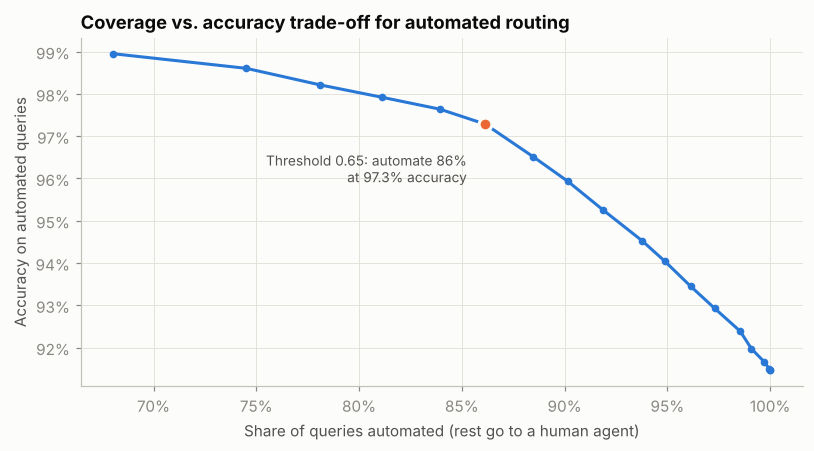

,threshold,automated_share,automated_accuracy,to_human_share
0,0.000000,100.0%,91.5%,0.0%
1,0.050000,100.0%,91.5%,0.0%
2,0.100000,100.0%,91.5%,0.0%
3,0.150000,99.7%,91.7%,0.3%
4,0.200000,99.1%,92.0%,0.9%
5,0.250000,98.5%,92.4%,1.5%
6,0.300000,97.3%,92.9%,2.7%
7,0.350000,96.1%,93.4%,3.9%
8,0.400000,94.9%,94.0%,5.1%
9,0.450000,93.8%,94.5%,6.2%


In [9]:
router_name = "TF-IDF words+chars + Logistic Regression"   # needs calibrated-ish probabilities
router = fitted[router_name]
proba = router.predict_proba(test.text)
table = intent.routing_table(test.category, proba, router.classes_, thresholds=np.round(np.arange(0, 0.91, 0.05), 2))

TARGET = 0.97
op = table[table.automated_accuracy >= TARGET].iloc[0]
print(f"Router model: {router_name}")
print(f"All queries automated: accuracy {table.iloc[0].automated_accuracy:.1%}")
print(f"To reach {TARGET:.0%} accuracy: threshold {op.threshold:.2f} -> automate {op.automated_share:.1%} of queries, "
      f"send {op.to_human_share:.1%} to agents")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.plot(table.automated_share, table.automated_accuracy, color=BLUE, lw=2, marker="o", ms=4)
ax.scatter([op.automated_share], [op.automated_accuracy], s=70, color=ORANGE, zorder=3, edgecolor=SURF, linewidth=2)
ax.annotate(f"Threshold {op.threshold:.2f}: automate {op.automated_share:.0%}\nat {op.automated_accuracy:.1%} accuracy",
            (op.automated_share, op.automated_accuracy), xytext=(-12, -38), textcoords="offset points",
            ha="right", fontsize=9, color=INK2)
ax.set(title="Coverage vs. accuracy trade-off for automated routing",
       xlabel="Share of queries automated (rest go to a human agent)", ylabel="Accuracy on automated queries")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); fig.savefig(FIG / "routing_tradeoff.png", bbox_inches="tight"); plt.show()
table.style.format({"automated_share": "{:.1%}", "automated_accuracy": "{:.1%}", "to_human_share": "{:.1%}"})

## 6. Learning curve: is more labeled data worth paying for?

Labeling costs money. Training the selected model on growing slices of the training data shows whether more
labels would still move accuracy. (This is a descriptive check made *after* model selection.)

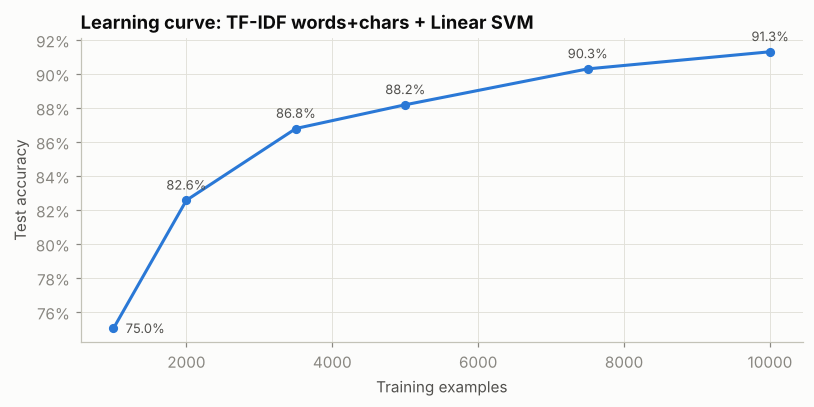

,train_fraction,examples,test_accuracy
0,10%,1000,75.03%
1,20%,2000,82.56%
2,35%,3501,86.79%
3,50%,5001,88.18%
4,75%,7502,90.29%
5,100%,10003,91.30%


In [10]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
fracs, accs = [0.1, 0.2, 0.35, 0.5, 0.75, 1.0], []
for f in fracs:
    sub = train if f == 1.0 else train_test_split(train, train_size=f, stratify=train.category, random_state=intent.SEED)[0]
    m = clone(best).fit(sub.text, sub.category); accs.append(accuracy_score(test.category, m.predict(test.text)))
lc = pd.DataFrame({"train_fraction": fracs, "examples": [int(len(train) * f) for f in fracs], "test_accuracy": accs})

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(lc.examples, lc.test_accuracy, color=BLUE, lw=2, marker="o", ms=5)
for x, y in zip(lc.examples, lc.test_accuracy):
    first = x == lc.examples.iloc[0]
    ax.annotate(f"{y:.1%}", (x, y), xytext=(8, -3) if first else (0, 7), textcoords="offset points",
                ha="left" if first else "center", fontsize=8.5, color=INK2)
ax.set(title=f"Learning curve: {best_name}", xlabel="Training examples", ylabel="Test accuracy")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.tight_layout(); fig.savefig(FIG / "learning_curve.png", bbox_inches="tight"); plt.show()
lc.style.format({"train_fraction": "{:.0%}", "test_accuracy": "{:.2%}"})

**Takeaway:** accuracy is still climbing at the full training set, but gains are flattening, so each additional
batch of labels buys less. Targeted labeling of the most-confused intents (Section 4) would likely pay off more than
labeling uniformly.

## 7. Summary and next steps

**Results** (exact figures are in the tables above and in the README)
- The CV-selected linear model on word + character TF-IDF clearly and significantly beats the bag-of-words baseline.
- It comes within about 2.4 points of fine-tuned BERT at a fraction of the compute.
- With confidence routing, about 86% of queries can be automated at 97% accuracy, with the rest sent to agents.

**Next steps**
- Fine-tune a small transformer (e.g., DistilBERT) and compare the accuracy gain against the cost of serving it.
- Calibrate probabilities (temperature or isotonic scaling) so the routing threshold means what it says.
- Add an out-of-scope detector for queries that match none of the 77 intents.
- Wrap the model in a small API with monitoring for drift in query mix and confidence.